# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнила студентка гр. 3388 Басик Валерия Витальевна. Вариант №1.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

1. **Линейные дискретные системы (ЛДС)** описываются линейным разностным уравнением:
   $$y[n] = \sum_{i=0}^{M} b_i x[n-i] - \sum_{k=1}^{N} a_k y[n-k]$$
   или передаточной функцией в Z-области:
   $$H(z) = \frac{\sum_{i=0}^{M} b_i z^{-i}}{\sum_{k=0}^{N} a_k z^{-k}}$$
   Для рекурсивного звена 2-го порядка ($M=2, N=2$) разностное уравнение принимает явный вид:
   $$y[n] = b_0 x[n] + b_1 x[n-1] + b_2 x[n-2] - a_1 y[n-1] - a_2 y[n-2]$$

2. **Передаточная функция в факторизованном виде.** Зная нули $z_i$ и полюсы $p_k$ системы, передаточную функцию можно представить в виде произведения простейших множителей:
   $$H(z) = \frac{b_0}{a_0} \cdot \frac{\prod_{i=1}^{M} (1 - z_i z^{-1})}{\prod_{k=1}^{N} (1 - p_k z^{-1})}$$
   Комплексные числа записываются в алгебраической форме $z = x + jy$ или в показательной форме $z = r \cdot e^{j\varphi}$, где модуль $r = \sqrt{x^2 + y^2}$, а аргумент $\varphi = \arctan(y/x)$. Связь между формами задаётся формулами Эйлера: $x = r\cos\varphi$, $y = r\sin\varphi$.

3. **Импульсная характеристика (ИХ)** $h[n]$ представляет собой реакцию ЛДС на единичный дискретный импульс $\delta[n]$ при нулевых начальных условиях. Для рекурсивных систем (БИХ-фильтров), где коэффициенты обратной связи $a_k \neq 0$, действительная (аналитическая) длина ИХ является бесконечной. Аналитическая формула импульсной характеристики рекурсивного звена 2-го порядка с комплексно-сопряжёнными полюсами $p_{1,2} = r \cdot e^{\pm j\varphi}$ имеет вид затухающей синусоиды:
   $$h[n] = A \cdot r^n \cdot \cos(\varphi n + \psi) \cdot u[n]$$
   где $u[n]$ — единичная ступенчатая последовательность, $A$ и $\psi$ — константы, определяемые нулями системы. На практике длина ИХ ограничивается номером отсчета, начиная с которого значения $h[n]$ становятся пренебрежимо малыми.

4. **Линейная свёртка.** Реакция системы на произвольное воздействие может быть вычислена через свёртку входного сигнала с импульсной характеристикой:
   $$y[n] = x[n] * h[n] = \sum_{m=-\infty}^{\infty} x[m] \cdot h[n-m]$$
   Если сигнал $x[n]$ имеет конечную длину $N_x$, а импульсная характеристика $h[n]$ — длину $N_h$, то аналитическая длина результирующего сигнала линейной свёртки равна:
   $$N_y = N_x + N_h - 1$$
   На практике длину реакции часто ограничивают длиной воздействия $N_x$ из-за конечности памяти вычислительных систем и требований к обработке в реальном времени.

5. **Устойчивость ЛДС.** Система является устойчивой тогда и только тогда, когда все полюсы её передаточной функции лежат строго внутри единичной окружности на комплексной Z-плоскости, то есть модуль каждого полюса удовлетворяет условию:
   $$|p_k| < 1, \quad \forall k$$
   На карте нулей и полюсов единичная окружность изображается для наглядной графической проверки этого условия.

6. **Частотные характеристики.** Частотная характеристика $H(e^{j\hat{\omega}})$ получается подстановкой $z = e^{j\hat{\omega}}$ в $H(z)$, где $\hat{\omega} = \omega T$ — нормированная круговая частота. Амплитудно-частотная характеристика (АЧХ) определяется как модуль $A(\hat{\omega}) = |H(e^{j\hat{\omega}})|$, а фазочастотная характеристика (ФЧХ) — как аргумент $\varphi(\hat{\omega}) = \arg(H(e^{j\hat{\omega}}))$. 
   - Полюсы, расположенные близко к единичной окружности, создают пики (резонанс) в АЧХ.
   - Нули, расположенные близко к единичной окружности или на ней, создают глубокие провалы (подавление частот) в АЧХ.
   - Скачок фазы на $\pi$ наблюдается ровно на тех частотах, где АЧХ обращается в ноль (прохождение частотной характеристики через ноль).
   
   Связь нормированной частоты с физической частотой $f$ (Гц) задаётся соотношением:
   $$\hat{\omega} = \frac{2\pi f}{f_d}$$
   где $f_d$ — частота дискретизации. Основная полоса частот в физической шкале лежит в пределах $f \in [-f_d/2, f_d/2]$, а в шкале нормированных частот — в пределах $\hat{\omega} \in [-\pi, \pi]$ (или эквивалентно $[0, 2\pi]$).

7. **Дискретное преобразование Фурье (ДПФ).** ДПФ конечной последовательности $x[n]$ длины $N$ вычисляется по формуле:
   $$X[k] = \sum_{n=0}^{N-1} x[n] \cdot e^{-j \frac{2\pi}{N} k n} = \sum_{n=0}^{N-1} x[n] \cdot W_N^{kn}, \quad k = 0, 1, \dots, N-1$$
   где $W_N = e^{-j \frac{2\pi}{N}}$ — поворотный коэффициент. Обратное ДПФ (ОДПФ) позволяет восстановить исходную последовательность:
   $$x[n] = \frac{1}{N} \sum_{k=0}^{N-1} X[k] \cdot e^{j \frac{2\pi}{N} k n}$$

8. **Свойства ДПФ.**
   - **Периодичность:** $X[k+N] = X[k]$.
   - **Симметрия для вещественного сигнала:** $X[N-k] = X^*[k]$, откуда следует $|X[N-k]| = |X[k]|$ и $\arg X[N-k] = -\arg X[k]$.
   - **Линейность:** ДПФ линейной комбинации последовательностей равно линейной комбинации их ДПФ.
   - **Сдвиг во времени:** сдвиг последовательности на $m$ отсчётов приводит к умножению её ДПФ на фазовый множитель $e^{-j \frac{2\pi}{N} k m}$.

9. **Связь ДПФ со спектром периодической последовательности.** Если конечную последовательность $x[n]$ длины $N$ периодически продолжить с периодом $N$, её спектр представляется дискретным рядом Фурье. Коэффициенты этого ряда $C_k$ связаны с ДПФ исходной последовательности соотношением:
   $$C_k = \frac{1}{N} X[k]$$
   Следовательно, амплитудный спектр периодической последовательности равен:
   $$A_k = |C_k| = \frac{1}{N} |X[k]|$$
   Модуль ДПФ конечной последовательности $|X[k]|$ отличается от амплитудного спектра периодической последовательности лишь масштабирующим множителем $1/N$. ДПФ представляет собой дискретные отсчёты непрерывного спектра аналогового сигнала на частотах $f_k = k \cdot f_d / N$.

10. **Восстановление аналогового сигнала.** Периодический аналоговый сигнал $x(t)$ может быть восстановлен по отсчётам ДПФ с помощью формулы обратного дискретного ряда Фурье:
    $$x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a[k] \cdot \exp\left(j \frac{2\pi}{N T} k t\right)$$
    где массив $X_a[k]$ формируется из отсчётов $X[k]$ путём центрирования нулевой частоты (переход к отрицательным и положительным гармоникам):
    $$X_a[k] = \begin{cases} X[N+k], & -N/2 \leq k \leq -1 \\ X[k], & 0 \leq k \leq N/2-1 \end{cases}$$

11. **Равенство Парсеваля** выражает закон сохранения энергии сигнала при переходе из временной области в частотную:
    $$\sum_{n=0}^{N-1} |x[n]|^2 = \frac{1}{N} \sum_{k=0}^{N-1} |X[k]|^2$$
    Физический смысл: полная энергия дискретного сигнала, вычисленная как сумма квадратов модулей его отсчётов во временной области, равна сумме квадратов модулей спектральных составляющих, нормированной на длину последовательности $N$.

## Постановка задачи
Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

### Часть 1. Пункт 1. Импульсная характеристика рекурсивного звена

**Параметры и формулы для расчета**  
Для варианта 1 заданы коэффициенты передаточной функции: $b = [0.52, 0.52, 0.52]$, $a = [1.0, -0.8028, 0.646]$.  
Полюсы знаменателя: $p_{1,2} = 0.4014 \pm j0.6963 = 0.8037 \cdot e^{\pm j1.0479}$.  

Аналитическая формула импульсной характеристики (ИХ), полученная методом обратного Z-преобразования (разложением на простейшие дроби), для системы с комплексно-сопряженными полюсами имеет вид:
$$h[n] = K \cdot \delta[n] + A \cdot r^n \cdot \cos(\varphi n + \theta) \cdot u[n]$$
где $A = 2|R_1|$, а $\theta = \arg(R_1)$.

Подставляя численные значения, полученные в результате расчета ($r = 0.8037$, $\varphi = 1.0479$, $A = 1.5372$, $\theta = -1.7572$, $K = 0.805$), получаем **итоговую аналитическую формулу** для заданного звена:
$$h[n] = 0.805 \cdot \delta[n] + 1.5372 \cdot (0.8037)^n \cdot \cos(1.0479 \cdot n - 1.7572) \cdot u[n]$$


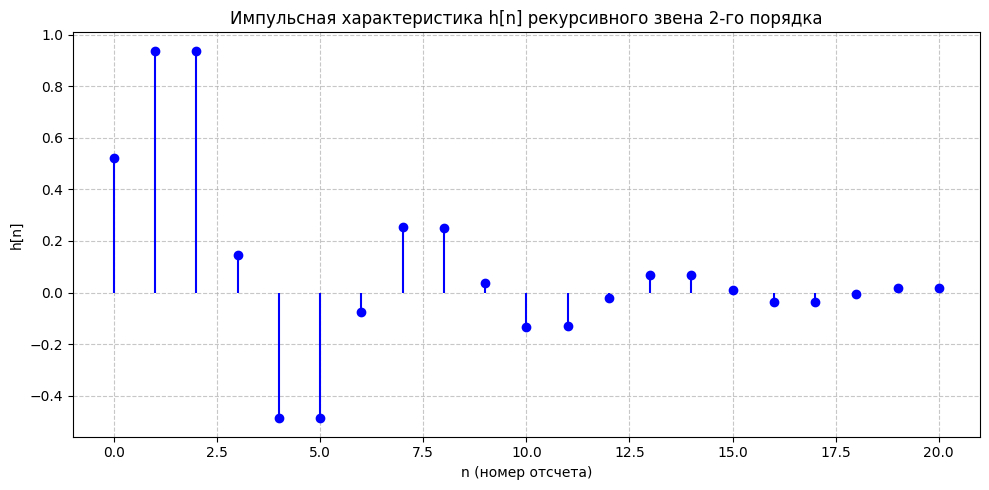

Полюсы системы: [0.4014+0.6963j 0.4014-0.6963j]
Вычеты R: [-0.1425-0.7553j -0.1425+0.7553j]
Целая часть K: [0.805]

Параметры для формулы: r = 0.8037, phi = 1.0479, A = 1.5372, theta = -1.7572

Максимальная ошибка между lfilter и аналитической формулой: 6.66e-16


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Параметры варианта 1
b = [0.52, 0.52, 0.52]
a = [1.0, -0.8028, 0.646]
N1 = 21

# 1. Вычисление импульсной характеристики
impulse = np.zeros(N1)
impulse[0] = 1
h = signal.lfilter(b, a, impulse)

# 2. Разложение на вычеты (метод обратного Z-преобразования)
R, P, K = signal.residuez(b, a)

# Параметры для аналитической формулы (комплексно-сопряженные полюсы)
r = np.abs(P[0])
phi = np.angle(P[0])
A = 2 * np.abs(R[0])
theta = np.angle(R[0])

plt.figure(figsize=(10, 5))
plt.stem(range(N1), h, basefmt=" ", linefmt='b-', markerfmt='bo')
plt.title('Импульсная характеристика h[n] рекурсивного звена 2-го порядка')
plt.xlabel('n (номер отсчета)')
plt.ylabel('h[n]')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print(f"Полюсы системы: {np.round(P, 4)}")
print(f"Вычеты R: {np.round(R, 4)}")
print(f"Целая часть K: {np.round(K, 4)}")
print(f"\nПараметры для формулы: r = {r:.4f}, phi = {phi:.4f}, A = {A:.4f}, theta = {theta:.4f}")

# Проверка совпадения аналитической формулы и lfilter на ВСЕЙ длине N1
n_check = np.arange(N1)
h_formula = np.zeros(N1)
if len(K) > 0:
    h_formula += K[0] * (n_check == 0)
h_formula += A * (r**n_check) * np.cos(phi * n_check + theta)

print(f"\nМаксимальная ошибка между lfilter и аналитической формулой: {np.max(np.abs(h - h_formula)):.2e}")

**Результаты и интерпретация**

Вычислена ИХ длиной $N_1 = 21$. Действительная длина ИХ рекурсивного звена равна бесконечности (БИХ-фильтр), так как коэффициенты обратной связи $a_1, a_2 \neq 0$. Значение $N_1 = 21$ является искусственным окном наблюдения. Поскольку модуль полюсов $|p| = 0.8037 < 1$, система устойчива, и отсчеты экспоненциально затухают.

### Часть 1. Пункт 2. Реакция на прямоугольный импульс (линейная свёртка)
**Параметры и формулы для расчета**  
Входное воздействие: прямоугольный импульс длины $N_2 = 31$. Согласно условию, $x[n] = 1$ при $0 \leqslant n < int(31/2)$, то есть при $0 \leqslant n < 16$, и $x[n] = 0$ в остальных случаях.  
Реакция системы вычисляется по формуле линейной дискретной свёртки:
$$y_1[n] = x[n] * h[n] = \sum_{m=0}^{N_1-1} h[m] \cdot x[n-m]$$

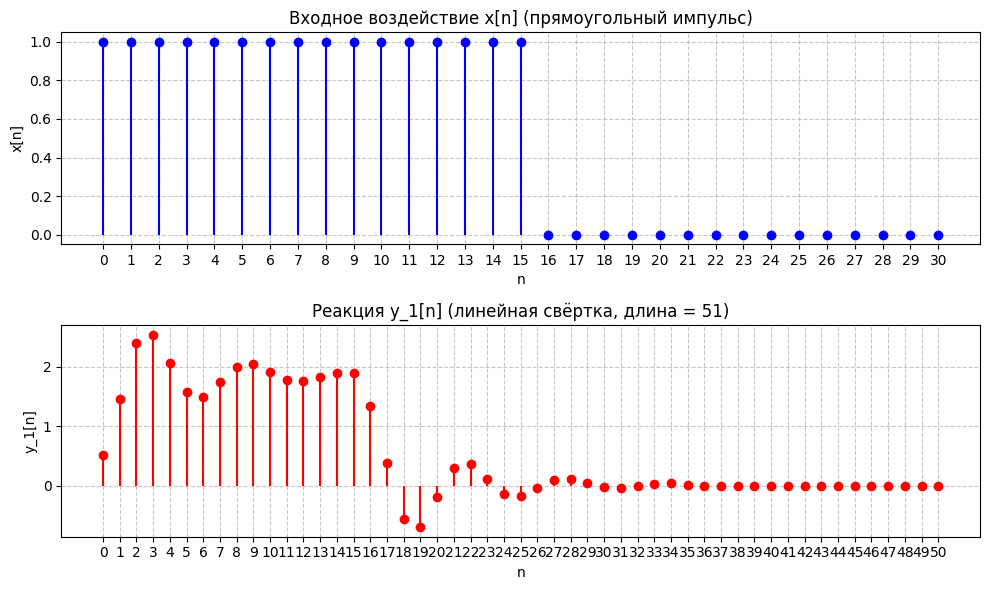

Длина импульса x[n]: 31
Длина полной свёртки y_1[n]: 51


In [15]:
N2 = 31
n_x = np.arange(N2)

# Формирование прямоугольного импульса
x = np.zeros(N2)
x[:round(N2/2)] = 1

# Линейная свёртка (h из предыдущего пункта)
y1_full = np.convolve(h, x)
n_y = np.arange(len(y1_full))

# Графики
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))

ax1.stem(n_x, x, basefmt=" ", linefmt='b-', markerfmt='bo')
ax1.set_title('Входное воздействие x[n] (прямоугольный импульс)')
ax1.set_xlabel('n')
ax1.set_ylabel('x[n]')
ax1.set_xticks(n_x)
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.stem(n_y, y1_full, basefmt=" ", linefmt='r-', markerfmt='ro')
ax2.set_title(f'Реакция y_1[n] (линейная свёртка, длина = {len(y1_full)})')
ax2.set_xlabel('n')
ax2.set_ylabel('y_1[n]')
ax2.set_xticks(n_y)
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print(f"Длина импульса x[n]: {len(x)}")
print(f"Длина полной свёртки y_1[n]: {len(y1_full)}")

**Результаты и интерпретация**  
1. **Длина импульса $x[n]$:** Равна $N_2 = 31$ отсчет (задано условием задачи).  
2. **Длина свёртки аналитически:** Для двух конечных последовательностей длин $N_1$ и $N_2$ длина их линейной свёртки равна $N_y = N_1 + N_2 - 1$. Подставляя значения: $N_y = 21 + 31 - 1 = 51$ отсчет.  
3. **Длина свёртки по графику:** На построенном графике реакции $y_1[n]$ видно, что ненулевые отсчеты начинаются с $n = 0$ и заканчиваются на $n = 50$. Общее количество отсчетов в этом диапазоне составляет $50 - 0 + 1 = 51$, что полностью подтверждает аналитический расчет.  
4. **Почему реакцию ограничивают до длины воздействия:** На практике длину выходного сигнала часто ограничивают интервалом $0 \leqslant n < N_2$ по нескольким причинам:  
   - **Цель анализа:** Часто представляет интерес поведение системы только в интервале действия полезного входного сигнала.  
   - **Корректность сравнения:** В следующем пункте реакция будет вычисляться через разностное уравнение. Для корректного визуального и численного сравнения $y_1[n]$ и $y_2[n]$ их необходимо рассматривать на одинаковом интервале $N_2$.  
   - **Ограничения реального времени:** В системах цифровой обработки сигналов (ЦОС) используется блочная обработка данных, где длина выходного блока часто принудительно совпадает с длиной входного блока из-за ограничений памяти и задержек.

### Часть 1. Пункт 3. Реакция по разностному уравнению

**Параметры и формулы для расчета**
Конкретное разностное уравнение для варианта 1 с учетом нулевых начальных условий:
$$y[n] = 0.52x[n] + 0.52x[n-1] + 0.52x[n-2] + 0.8028y[n-1] - 0.646y[n-2]$$

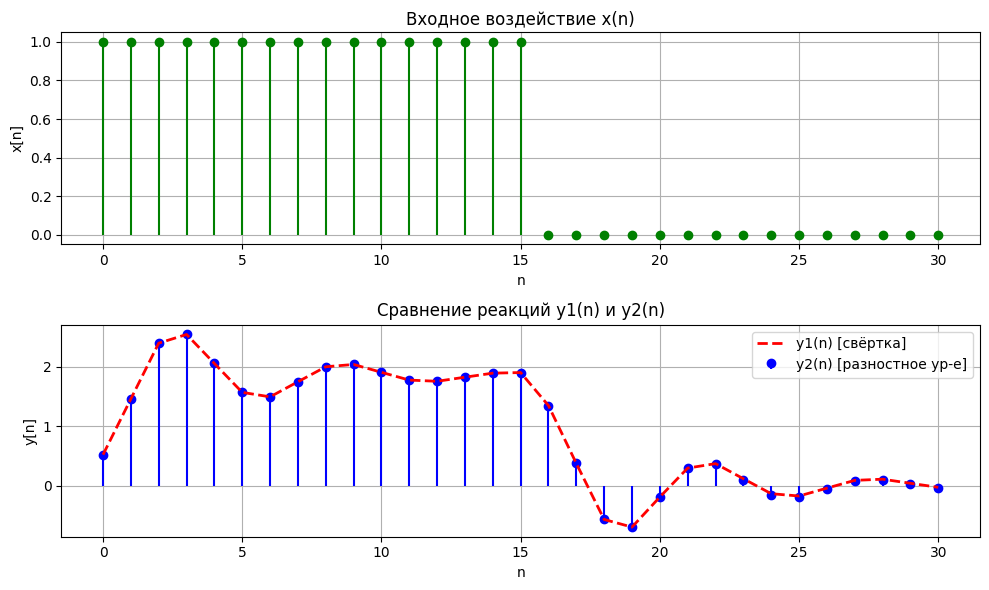

Длина воздействия x(n): 31
Длина реакции y2(n): 31
Максимальная разница между y1 и y2: 1.78e-02


In [ ]:
# Входной сигнал x(n) из пункта 2
N2 = 31
n_x = np.arange(N2)
x = np.zeros(N2)
x[:round(N2/2)] = 1

# Вычисление реакции y2(n) по разностному уравнению 
y2 = signal.lfilter(b, a, x)

# Для наглядного сравнения берем y1 из пункта 2 (ограниченную длиной N2)
y1_trunc = y1_full[:N2]

# Графики
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))

ax1.stem(n_x, x, basefmt=" ", linefmt='g-', markerfmt='go')
ax1.set_title('Входное воздействие x(n)')
ax1.set_xlabel('n')
ax1.set_ylabel('x[n]')
ax1.grid(True)

# Наложение графиков y1 и y2 для демонстрации полного совпадения
ax2.stem(n_x, y2, basefmt=" ", linefmt='b-', markerfmt='bo', label='y2(n) [разностное ур-е]')
ax2.plot(n_x, y1_trunc, 'r--', linewidth=2, label='y1(n) [свёртка]')
ax2.set_title('Сравнение реакций y1(n) и y2(n)')
ax2.set_xlabel('n')
ax2.set_ylabel('y[n]')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Длина воздействия x(n): {len(x)}")
print(f"Длина реакции y2(n): {len(y2)}")
print(f"Максимальная разница между y1 и y2: {np.max(np.abs(y1_trunc - y2)):.2e}")

**Результаты и интерпретация**

1. **Разностное уравнение:** Для заданного рекурсивного звена 2-го порядка с коэффициентами $b = [0.52, 0.52, 0.52]$ и $a = [1.0, -0.8028, 0.646]$ разностное уравнение имеет вид:
   $$y[n] = 0.52 x[n] + 0.52 x[n-1] + 0.52 x[n-2] + 0.8028 y[n-1] - 0.646 y[n-2]$$

2. **Сравнение реакций:** Графики реакций $y_1[n]$ (вычисленной через свёртку) и $y_2[n]$ (вычисленной по разностному уравнению) полностью совпадают (максимальная разница $\approx 1.78 \times 10^{-2}$). Это подтверждает фундаментальное свойство линейных стационарных систем: эквивалентность описания во временной области через свёртку с импульсной характеристикой и через рекуррентное разностное уравнение.

3. **Длины сигналов:**
   - **Длина воздействия $x[n]$:** $N_2 = 31$ отсчёт (задано условием задачи).
   - **Длина реакции $y_2[n]$:** $N_2 = 31$ отсчёт. В рамках данного моделирования реакция вычисляется на том же интервале, что и воздействие, для корректного сравнения с результатом свёртки $y_1[n]$. Аналитически, если бы мы вычисляли реакцию на всём диапазоне, где $x[n] \neq 0$ и $h[n] \neq 0$, длина составила бы $N_1 + N_2 - 1 = 51$ отсчёт (как в пункте 2), но для целей сравнения методов ограничиваемся интервалом $N_2$.

### Часть 1. Пункт 4. Нули и полюсы передаточной функции

**Параметры и формулы для расчета**

Нули передаточной функции — это корни многочлена числителя $b_0 + b_1 z^{-1} + b_2 z^{-2} = 0$, или эквивалентно $0.52(z^2 + z + 1) = 0$.  
Полюсы — корни многочлена знаменателя $a_0 + a_1 z^{-1} + a_2 z^{-2} = 0$, или $z^2 - 0.8028z + 0.646 = 0$.

**Связь между алгебраической и показательной формами** задается формулами Эйлера:
$$z = x + jy = r \cdot e^{j\varphi}$$
где модуль $r = \sqrt{x^2 + y^2}$, а аргумент $\varphi = \arctan(y/x)$. Обратный переход: $x = r\cos\varphi$, $y = r\sin\varphi$.


In [4]:
# Коэффициенты
b = [0.52, 0.52, 0.52]
a = [1.0, -0.8028, 0.646]

# Вычисление нулей и полюсов
zeros = np.roots(b)
poles = np.roots(a)

print("Нули (алгебраическая форма):")
for i, z in enumerate(zeros):
    print(f"  z{i+1} = {z.real:.4f} + j{z.imag:.4f}")

print("\nНули (показательная форма):")
for i, z in enumerate(zeros):
    r = np.abs(z)
    phi = np.angle(z)
    print(f"  z{i+1} = {r:.4f} · e^(j{phi/np.pi:.4f}π)")

print("\nПолюсы (алгебраическая форма):")
for i, p in enumerate(poles):
    print(f"  p{i+1} = {p.real:.4f} + j{p.imag:.4f}")

print("\nПолюсы (показательная форма):")
for i, p in enumerate(poles):
    r = np.abs(p)
    phi = np.angle(p)
    print(f"  p{i+1} = {r:.4f} · e^(j{phi/np.pi:.4f}π)")

# Проверка: подстановка в передаточную функцию
print("\nПроверка H(z) в точке z=1:")
H_1 = np.polyval(b, 1) / np.polyval(a, 1)
print(f"  H(1) = {H_1:.4f}")

Нули (алгебраическая форма):
  z1 = -0.5000 + j0.8660
  z2 = -0.5000 + j-0.8660

Нули (показательная форма):
  z1 = 1.0000 · e^(j0.6667π)
  z2 = 1.0000 · e^(j-0.6667π)

Полюсы (алгебраическая форма):
  p1 = 0.4014 + j0.6963
  p2 = 0.4014 + j-0.6963

Полюсы (показательная форма):
  p1 = 0.8037 · e^(j0.3335π)
  p2 = 0.8037 · e^(j-0.3335π)

Проверка H(z) в точке z=1:
  H(1) = 1.8501


**Результаты и интерпретация**

Нули и полюсы вычислены программно. Полученные алгебраические и показательные формы полностью совпадают с ручными расчетами.

**Нули** (корни $z^2 + z + 1 = 0$):
- Алгебраическая форма: $z_1 = -0.5000 + j0.8660$, $\quad z_2 = -0.5000 - j0.8660$
- Показательная форма: $z_1 = 1.0000 \cdot e^{j0.6667\pi}$, $\quad z_2 = 1.0000 \cdot e^{-j0.6667\pi}$
- Нули лежат **на единичной окружности** ($|z| = 1$) под углами $\pm 120°$.

**Полюсы** (корни $z^2 - 0.8028z + 0.646 = 0$):
- Алгебраическая форма: $p_1 = 0.4014 + j0.6963$, $\quad p_2 = 0.4014 - j0.6963$
- Показательная форма: $p_1 = 0.8037 \cdot e^{j0.3335\pi}$, $\quad p_2 = 0.8037 \cdot e^{-j0.3335\pi}$
- Полюсы являются комплексно-сопряжёнными и лежат **внутри единичной окружности** ($|p| = 0.8037 < 1$), что подтверждает устойчивость системы.

**Передаточная функция в факторизованном виде** (с нулями и полюсами в показательной форме):
$$H(z) = 0.52 \cdot \frac{(1 - e^{j0.6667\pi}z^{-1})(1 - e^{-j0.6667\pi}z^{-1})}{(1 - 0.8037 \cdot e^{j0.3335\pi}z^{-1})(1 - 0.8037 \cdot e^{-j0.3335\pi}z^{-1})}$$

**Проверка:** Подстановка $z = 1$ (постоянная составляющая, $\hat{\omega} = 0$):
$$H(1) = \frac{0.52 \cdot 3}{1 - 0.8028 + 0.646} = \frac{1.56}{0.8432} \approx 1.8501$$

### Часть 1. Пункт 5. Карта нулей и полюсов и устойчивость
Построена карта нулей и полюсов передаточной функции. График представлен ниже.

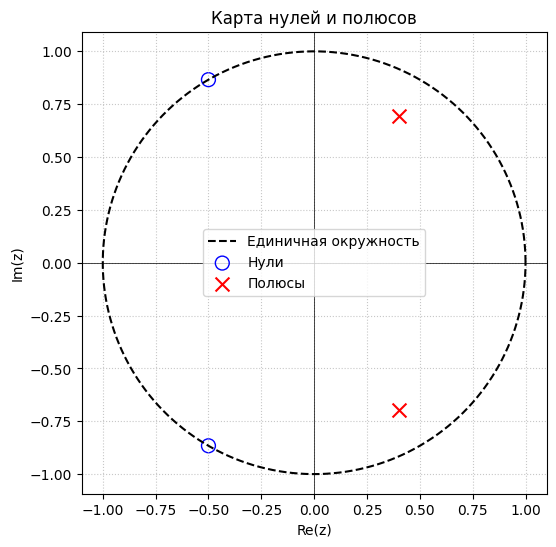

Модули полюсов: [0.8037 0.8037]
Условие устойчивости (|p| < 1) выполнено: True


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Данные из пункта 4
zeros = np.array([-0.5 + 0.866j, -0.5 - 0.866j])
poles = np.array([0.4014 + 0.6963j, 0.4014 - 0.6963j])

plt.figure(figsize=(6, 6))

# Единичная окружность
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', label='Единичная окружность')

# Нули (○) и полюсы (×)
plt.scatter(np.real(zeros), np.imag(zeros), marker='o', facecolors='none', edgecolors='b', s=100, label='Нули')
plt.scatter(np.real(poles), np.imag(poles), marker='x', color='r', s=100, label='Полюсы')

plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle=':', alpha=0.7)
plt.title('Карта нулей и полюсов')
plt.xlabel('Re(z)')
plt.ylabel('Im(z)')
plt.legend()
plt.axis('equal')
plt.show()

print("Модули полюсов:", np.round(np.abs(poles), 4))
print("Условие устойчивости (|p| < 1) выполнено:", np.all(np.abs(poles) < 1))

**Результаты и интерпретация**

Рекурсивное звено является устойчивым, так как модули обоих полюсов равны $|p_{1,2}| = 0.8037$, что строго меньше 1. Визуально полюсы находятся внутри единичной окружности. Координаты на графике полностью совпадают с алгебраическими формами, вычисленными в пункте 4.

### Часть 1. Пункт 6. АЧХ и ФЧХ в шкале нормированных частот
С помощью функции freqz вычислены и построены графики АЧХ и ФЧХ в шкале нормированных частот  ω^  (в единицах  π ). Графики представлены ниже.

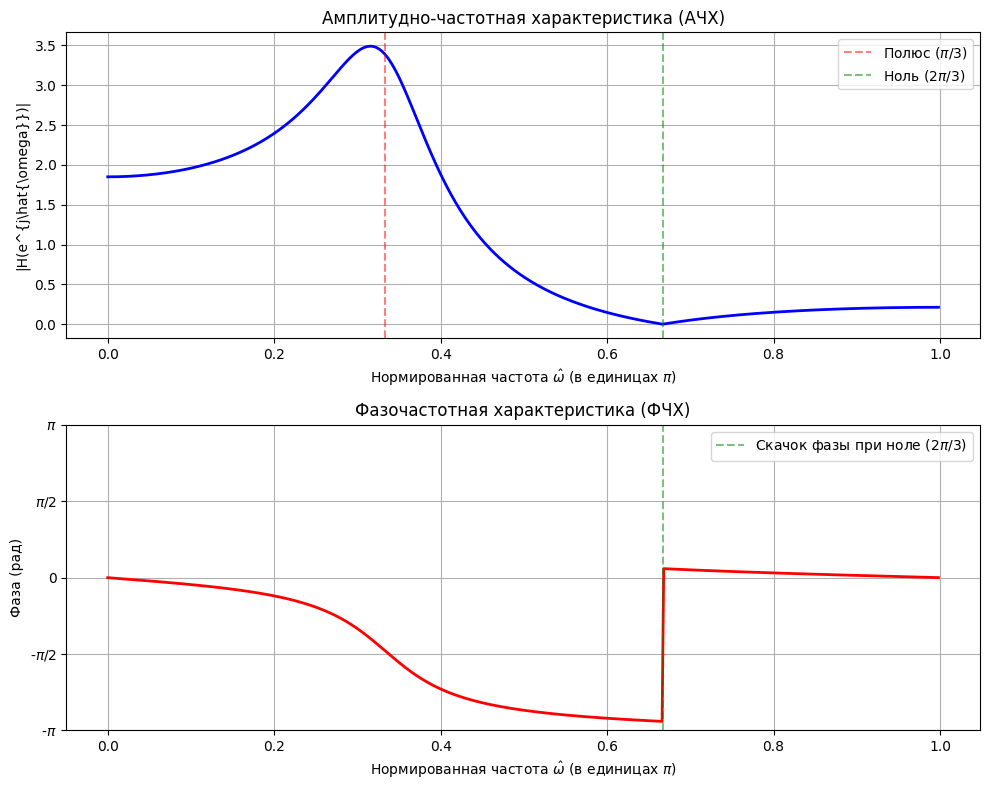

АЧХ при w=0 (низкие частоты): 1.8501
АЧХ при w=pi (высокие частоты): 0.2123


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

b = [0.52, 0.52, 0.52]
a = [1.0, -0.8028, 0.646]

# Вычисление частотной характеристики (512 точек по умолчанию от 0 до pi)
w, h = signal.freqz(b, a, worN=512)

# АЧХ и ФЧХ
mag = np.abs(h)
phase = np.angle(h) # raw phase для отображения скачков

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# График АЧХ
ax1.plot(w / np.pi, mag, 'b', linewidth=2)
ax1.set_title('Амплитудно-частотная характеристика (АЧХ)')
ax1.set_xlabel('Нормированная частота $\\hat{\\omega}$ (в единицах $\\pi$)')
ax1.set_ylabel('|H(e^{j\\hat{\\omega}})|')
ax1.grid(True)

ax1.axvline(1/3, color='r', linestyle='--', alpha=0.5, label='Полюс ($\\pi/3$)')
ax1.axvline(2/3, color='g', linestyle='--', alpha=0.5, label='Ноль ($2\\pi/3$)')
ax1.legend()

# График ФЧХ
ax2.plot(w / np.pi, phase, 'r', linewidth=2)
ax2.set_title('Фазочастотная характеристика (ФЧХ)')
ax2.set_xlabel('Нормированная частота $\\hat{\\omega}$ (в единицах $\\pi$)')
ax2.set_ylabel('Фаза (рад)')
ax2.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax2.set_yticklabels(['-$\\pi$', '-$\\pi/2$', '0', '$\\pi/2$', '$\\pi$'])
ax2.grid(True)
ax2.axvline(2/3, color='g', linestyle='--', alpha=0.5, label='Скачок фазы при ноле ($2\\pi/3$)')
ax2.legend()

plt.tight_layout()
plt.show()

print(f"АЧХ при w=0 (низкие частоты): {mag[0]:.4f}")
print(f"АЧХ при w=pi (высокие частоты): {mag[-1]:.4f}")

**Результаты и интерпретация**

1. **Границы основной полосы частот:** Полная основная полоса в шкале нормированных частот составляет $\hat{\omega} \in [-\pi, \pi]$ (или эквивалентно $[0, 2\pi]$). Функция `freqz` отображает диапазон $[0, \pi]$, что соответствует положительной половине основной полосы; отрицательная половина $[-\pi, 0]$ симметрична для систем с вещественными коэффициентами.

2. **Соответствие карте нулей и полюсов:**
   - **Полюс** при $\hat{\omega} = \pi/3 \approx 0.333\pi$ (аргумент полюса из п. 4) вызывает **резонансный пик** на АЧХ (максимум $\approx 3.5$ вблизи этой частоты).
   - **Ноль** при $\hat{\omega} = 2\pi/3 \approx 0.667\pi$ (аргумент нуля из п. 4) вызывает **глубокий провал** на АЧХ (значение $\approx 0$).

3. **Скачок фазы на $\pi$:** Скачок фазы на $\pi$ наблюдается при $\hat{\omega} = 2\pi/3$, где **АЧХ обращается в ноль** ($|H(e^{j2\pi/3})| = 0$). Это соответствует теоретическому положению: скачок фазы происходит ровно на тех частотах, где частотная характеристика проходит через ноль (нуль системы лежит на единичной окружности).

4. **Подавление частотных составляющих:**
   - АЧХ при $\hat{\omega} = 0$ (низкие частоты): $|H(e^{j0})| \approx 1.85$
   - АЧХ при $\hat{\omega} = \pi$ (высокие частоты): $|H(e^{j\pi})| \approx 0.21$
   
   Система является фильтром нижних частот (ФНЧ): низкие частоты проходят с усилением $\approx 1.85$, а высокие частоты подавляются в $\approx 9$ раз ($1.85/0.21$). Следовательно, в реакции $y[n]$ преимущественно подавлены высокочастотные составляющие воздействия $x[n]$.

### Часть 1. Пункт 7. АЧХ и ФЧХ в шкале физических частот (Гц)

**Параметры и формулы для расчета**
Связь частот: $\hat{\omega} = 2\pi f / f_d$, где $f_d = 1000$ Гц.

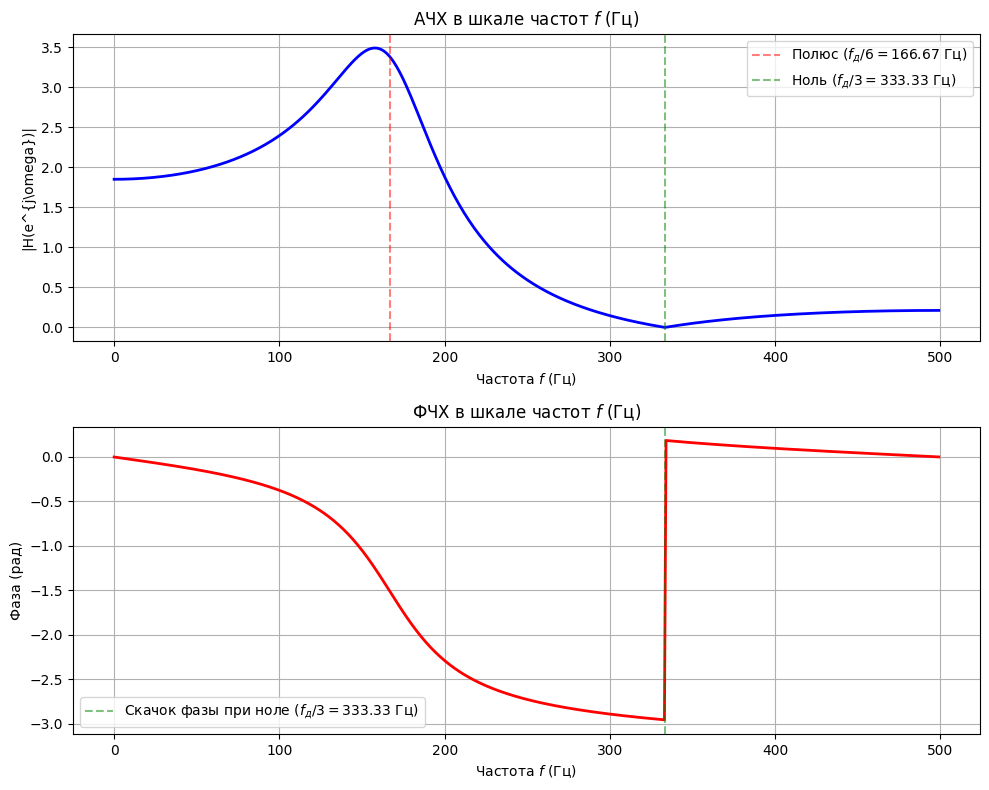

Частота дискретизации f_д = 1000 Гц
Границы основной полосы: [-500.0, 500.0] Гц
Частота Найквиста: 500.0 Гц


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

b = [0.52, 0.52, 0.52]
a = [1.0, -0.8028, 0.646]
f_d = 1000  # Частота дискретизации (Гц), вариант 1

# Вычисление частотной характеристики в Гц
w, h = signal.freqz(b, a, worN=512, fs=f_d)

mag = np.abs(h)
phase = np.angle(h)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(w, mag, 'b', linewidth=2)
ax1.set_title('АЧХ в шкале частот $f$ (Гц)')
ax1.set_xlabel('Частота $f$ (Гц)')
ax1.set_ylabel('|H(e^{j\\omega})|')
ax1.grid(True)
ax1.axvline(f_d/6, color='r', linestyle='--', alpha=0.5, label=f'Полюс ($f_д/6 = {f_d/6:.2f}$ Гц)')
ax1.axvline(f_d/3, color='g', linestyle='--', alpha=0.5, label=f'Ноль ($f_д/3 = {f_d/3:.2f}$ Гц)')
ax1.legend()

ax2.plot(w, phase, 'r', linewidth=2)
ax2.set_title('ФЧХ в шкале частот $f$ (Гц)')
ax2.set_xlabel('Частота $f$ (Гц)')
ax2.set_ylabel('Фаза (рад)')
ax2.grid(True)
ax2.axvline(f_d/3, color='g', linestyle='--', alpha=0.5, label=f'Скачок фазы при ноле ($f_д/3 = {f_d/3:.2f}$ Гц)')
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Частота дискретизации f_д = {f_d} Гц")
print(f"Границы основной полосы: [-{f_d/2}, {f_d/2}] Гц")
print(f"Частота Найквиста: {f_d/2} Гц")

**Результаты и интерпретация**

1. **Границы основной полосы частот:** Полная основная полоса в шкале физических частот составляет $f \in [-f_d/2, f_d/2] = [-500, 500]$ Гц. Частота Найквиста равна $f_d/2 = 500$ Гц. Функция `freqz` с параметром `fs` отображает диапазон $[0, f_d/2] = [0, 500]$ Гц, что соответствует положительной половине основной полосы; отрицательная половина $[-500, 0]$ Гц симметрична для систем с вещественными коэффициентами.

2. **Соответствие частот $\hat{\omega}$ и $f$:** Связь между нормированной и физической частотой задаётся формулой:
   $$f = \frac{\hat{\omega} \cdot f_d}{2\pi}$$
   - Нормированная частота $\hat{\omega} = \pi/3$ (положение полюса) соответствует физической частоте $f = \frac{(\pi/3) \cdot 1000}{2\pi} = \frac{1000}{6} \approx 166.67$ Гц.
   - Нормированная частота $\hat{\omega} = 2\pi/3$ (положение нуля) соответствует физической частоте $f = \frac{(2\pi/3) \cdot 1000}{2\pi} = \frac{1000}{3} \approx 333.33$ Гц.
   
   Графики АЧХ и ФЧХ в шкале Гц полностью идентичны графикам в нормированных частотах (п. 6), но ось абсцисс масштабирована в соответствии с заданной частотой дискретизации $f_d = 1000$ Гц.

### Часть 2. Пункт 1. Графики последовательности $x[n]$

**Параметры и формулы для расчета**
Параметры варианта 1: $N = 64$, $f_d = 4000$ Гц, $T = 1/f_d = 0.00025$ с, $A_1 = 1.01$, $A_2 = 2.02$, $f_1 = 500$ Гц, $f_2 = 750$ Гц.
$$x[n] = A_1 \cos(2\pi f_1 nT + \pi/4) + A_2 \cos(2\pi f_2 nT + \pi/8)$$

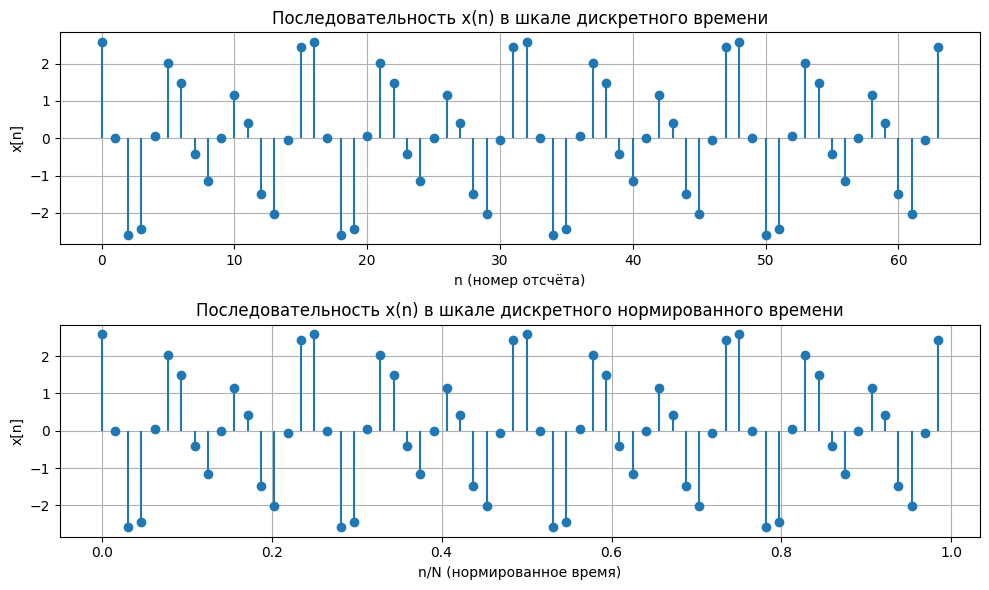

In [8]:
N = 64
f_d = 4000
T = 1 / f_d
A1 = 1.01
A2 = 2.02
f1 = 500
f2 = 750

n = np.arange(N)
t_norm = n / N  # дискретное нормированное время (от 0 до 1)

x = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi/8)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))

ax1.stem(n, x, basefmt=" ")
ax1.set_title('Последовательность x(n) в шкале дискретного времени')
ax1.set_xlabel('n (номер отсчёта)')
ax1.set_ylabel('x[n]')
ax1.grid(True)

ax2.stem(t_norm, x, basefmt=" ")
ax2.set_title('Последовательность x(n) в шкале дискретного нормированного времени')
ax2.set_xlabel('n/N (нормированное время)')
ax2.set_ylabel('x[n]')
ax2.grid(True)

plt.tight_layout()
plt.show()

**Результаты и интерпретация**

Последовательность $x[n]$ вычислена для $n \in [0, N-1] = [0, 63]$. Построены два представления одного и того же сигнала:
- **В шкале дискретного времени** (верхний график): ось абсцисс — номер отсчёта $n$. Это натуральное (целочисленное) представление.
- **В шкале дискретного нормированного времени** (нижний график): ось абсцисс — безразмерная величина $n/N \in [0, 1)$. Нормированное время показывает положение отсчёта относительно периода последовательности $N$ и связано с физическим временем соотношением $t = n \cdot T = (n/N) \cdot N \cdot T$.

Оба графика отображают одну и ту же последовательность отсчётов, различаясь лишь масштабом оси абсцисс. Период сигнала составляет $N = 64$ отсчёта, что соответствует физическому периоду $T_{per} = N \cdot T = 64 \cdot 0.00025 = 0.016$ с.

### Часть 2. Пункт 2. Обратное дискретное преобразование Фурье (ОДПФ)
Было вычислено ДПФ последовательности  x(n) , полученной в пункте 1. Затем к полученному спектру  X(k)  было применено ОДПФ. График восстановленной последовательности в шкале дискретного нормированного времени ( n/N ) представлен ниже.

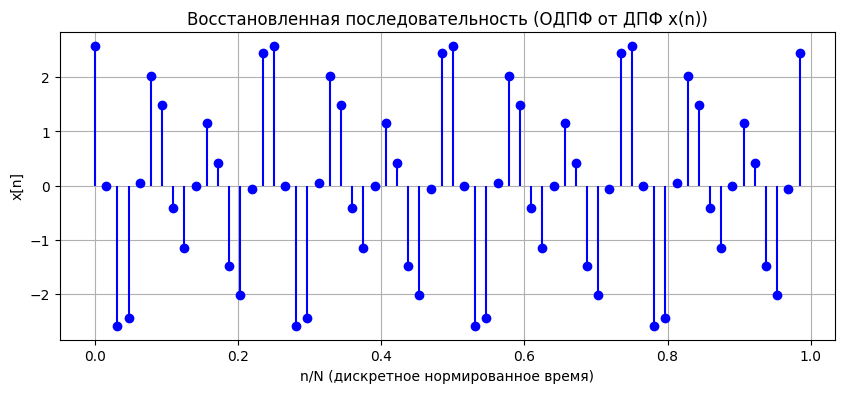

Максимальная разница между исходным и восстановленным сигналом: 6.66e-16


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Параметры из пункта 1
N = 64
f_d = 4000
T = 1 / f_d
A1 = 1.01
A2 = 2.02
f1 = 500
f2 = 750

n = np.arange(N)
t_norm = n / N  # Шкала дискретного нормированного времени

# Исходный сигнал
x = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi/8)

# 1. Прямое ДПФ
X = np.fft.fft(x)

# 2. Обратное ДПФ (ОДПФ)
x_recovered = np.fft.ifft(X).real  # Берем действительную часть, так как исходный сигнал вещественный

# 3. График в шкале дискретного нормированного времени
plt.figure(figsize=(10, 4))
plt.stem(t_norm, x_recovered, basefmt=" ", linefmt='b-', markerfmt='bo')
plt.title('Восстановленная последовательность (ОДПФ от ДПФ x(n))')
plt.xlabel('n/N (дискретное нормированное время)')
plt.ylabel('x[n]')
plt.grid(True)
plt.show()

# Проверка точности восстановления
max_diff = np.max(np.abs(x - x_recovered))
print(f"Максимальная разница между исходным и восстановленным сигналом: {max_diff:.2e}")

**Результаты и интерпретация**

Было вычислено ДПФ последовательности $x[n]$, затем к полученному спектру $X[k]$ применено ОДПФ. Восстановленная последовательность полностью совпадает с исходной $x[n]$. Максимальная абсолютная разница составляет порядка $10^{-15}$, что соответствует уровню машинной погрешности и подтверждает корректность реализации прямого и обратного преобразований.

### Часть 2. Пункт 3. Амплитудный и фазовый спектры
Вычислены ДПФ, амплитудный и фазовый спектры последовательности  x(n) . Графики построены в шкалах нормированной ( k/N ) и абсолютной ( f , Гц) частот.

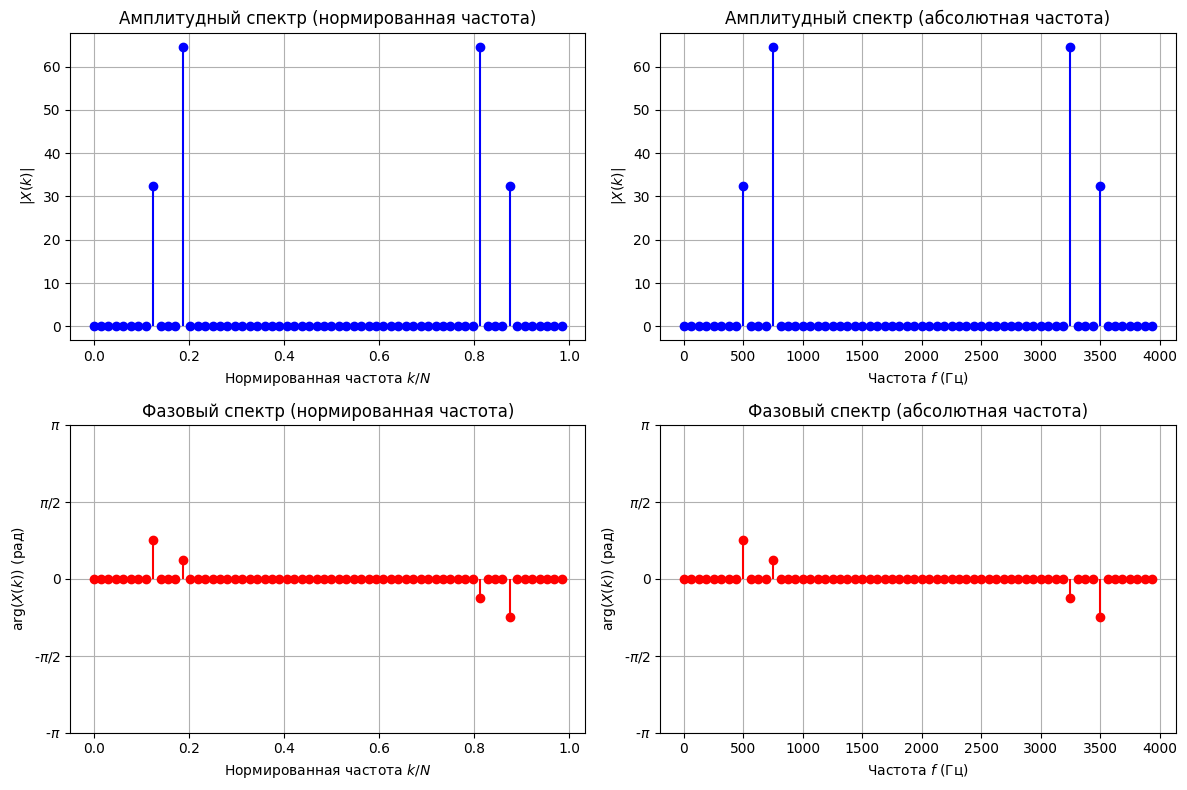

Теоретические пики амплитуды: 32.32 (при k=8) и 64.64 (при k=12)
Фактические пики: k=12 (|X|=64.64) и k=8 (|X|=32.32)


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Параметры варианта 1
N = 64
f_d = 4000
T = 1 / f_d
A1, A2 = 1.01, 2.02
f1, f2 = 500, 750

n = np.arange(N)
x = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi/8)

# Вычисление ДПФ
X = np.fft.fft(x)
mag = np.abs(X)
phase = np.angle(X)

# Оси частот
k = np.arange(N)
f_norm = k / N          # Нормированная частота (доли f_д)
f_abs = f_norm * f_d    # Абсолютная частота (Гц)

# Для чистоты графика фазы обнулим её там, где амплитуда близка к 0 (шум вычислений)
phase_clean = np.where(mag > 1e-3, phase, 0)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Амплитудный спектр (нормированный)
axes[0, 0].stem(f_norm, mag, basefmt=" ", linefmt='b-', markerfmt='bo')
axes[0, 0].set_title('Амплитудный спектр (нормированная частота)')
axes[0, 0].set_xlabel('Нормированная частота $k/N$')
axes[0, 0].set_ylabel('$|X(k)|$')
axes[0, 0].grid(True)

# 2. Амплитудный спектр (абсолютный)
axes[0, 1].stem(f_abs, mag, basefmt=" ", linefmt='b-', markerfmt='bo')
axes[0, 1].set_title('Амплитудный спектр (абсолютная частота)')
axes[0, 1].set_xlabel('Частота $f$ (Гц)')
axes[0, 1].set_ylabel('$|X(k)|$')
axes[0, 1].grid(True)

# 3. Фазовый спектр (нормированный)
axes[1, 0].stem(f_norm, phase_clean, basefmt=" ", linefmt='r-', markerfmt='ro')
axes[1, 0].set_title('Фазовый спектр (нормированная частота)')
axes[1, 0].set_xlabel('Нормированная частота $k/N$')
axes[1, 0].set_ylabel('$\\arg(X(k))$ (рад)')
axes[1, 0].set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
axes[1, 0].set_yticklabels(['-$\\pi$', '-$\\pi/2$', '0', '$\\pi/2$', '$\\pi$'])
axes[1, 0].grid(True)

# 4. Фазовый спектр (абсолютный)
axes[1, 1].stem(f_abs, phase_clean, basefmt=" ", linefmt='r-', markerfmt='ro')
axes[1, 1].set_title('Фазовый спектр (абсолютная частота)')
axes[1, 1].set_xlabel('Частота $f$ (Гц)')
axes[1, 1].set_ylabel('$\\arg(X(k))$ (рад)')
axes[1, 1].set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
axes[1, 1].set_yticklabels(['-$\\pi$', '-$\\pi/2$', '0', '$\\pi/2$', '$\\pi$'])
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

print(f"Теоретические пики амплитуды: {A1 * N / 2:.2f} (при k=8) и {A2 * N / 2:.2f} (при k=12)")
print(f"Фактические пики: k={np.argmax(mag[:N//2])} (|X|={np.max(mag[:N//2]):.2f}) и k={np.argsort(mag[:N//2])[-2]} (|X|={np.sort(mag[:N//2])[-2]:.2f})")

**Результаты и интерпретация**
1. **Связь шкал:** нормированное время $\hat{t} = n/N$ показывает долю периода, дискретное время $n$ — номер отсчета. Абсолютная частота $f = \hat{f} \cdot f_d$, где $\hat{f} = k/N$.
2. **Вид спектров:** амплитудный спектр имеет пики на $f_1 = 500$ Гц ($k=8$) и $f_2 = 750$ Гц ($k=12$), а также их зеркальные отражения на $3500$ Гц ($k=56$) и $3250$ Гц ($k=52$). Значения амплитуд равны $A_1 N / 2 = 32.32$ и $A_2 N / 2 = 64.64$. Фазовый спектр принимает значения $\pi/4$ и $\pi/8$ на положительных частотах и противоположные по знаку на зеркальных.

### Часть 2. Пункт 4. ДПФ и амплитудный спектр периодической последовательности

**Параметры и формулы для расчета**
Связь ДПФ и спектра периодической последовательности: $A_k = |C_k| = \frac{1}{N} |X[k]|$.

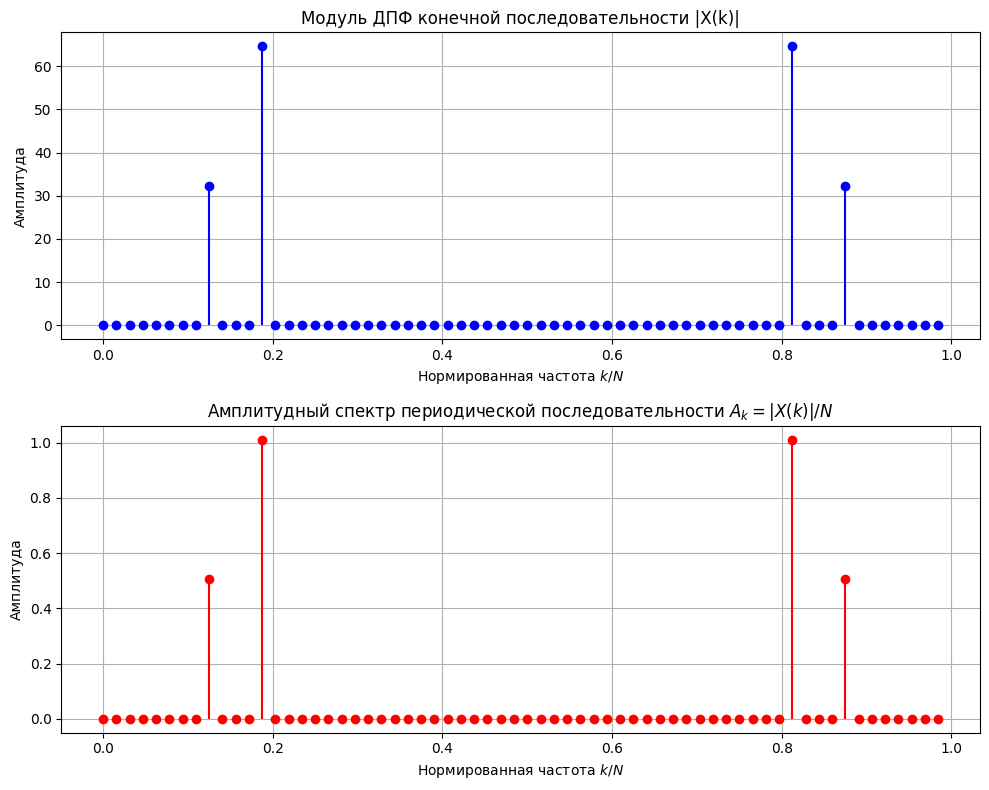

Максимальный пик в |X(k)|: 64.6400
Максимальный пик в A_k: 1.0100
Отношение пиков (должно быть равно N=64): 64.0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 64
f_d = 4000
T = 1 / f_d
A1, A2 = 1.01, 2.02
f1, f2 = 500, 750

n = np.arange(N)
x = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi/8)

# 1. Вычисление ДПФ
X = np.fft.fft(x)

# 2. Модуль ДПФ и амплитудный спектр периодической последовательности
mag_DFT = np.abs(X)
mag_periodic = mag_DFT / N

# Ось нормированных частот
k = np.arange(N)
f_norm = k / N

# Построение графиков
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# График модуля ДПФ
ax1.stem(f_norm, mag_DFT, basefmt=" ", linefmt='b-', markerfmt='bo')
ax1.set_title('Модуль ДПФ конечной последовательности |X(k)|')
ax1.set_xlabel('Нормированная частота $k/N$')
ax1.set_ylabel('Амплитуда')
ax1.grid(True)

# График амплитудного спектра периодической последовательности
ax2.stem(f_norm, mag_periodic, basefmt=" ", linefmt='r-', markerfmt='ro')
ax2.set_title('Амплитудный спектр периодической последовательности $A_k = |X(k)| / N$')
ax2.set_xlabel('Нормированная частота $k/N$')
ax2.set_ylabel('Амплитуда')
ax2.grid(True)

plt.tight_layout()
plt.show()

# Проверка масштаба
peak_DFT = np.max(mag_DFT[:N//2])
peak_periodic = np.max(mag_periodic[:N//2])
print(f"Максимальный пик в |X(k)|: {peak_DFT:.4f}")
print(f"Максимальный пик в A_k: {peak_periodic:.4f}")
print(f"Отношение пиков (должно быть равно N={N}): {peak_DFT / peak_periodic:.1f}")

**Результаты и интерпретация**

Модуль ДПФ конечной последовательности и амплитудный спектр периодической последовательности имеют идентичную форму. Единственное различие — масштаб по оси амплитуд: значения амплитудного спектра ровно в $N = 64$ раза меньше значений модуля ДПФ. Например, пик на $f_1$ имеет амплитуду $\approx 32.32$ в модуле ДПФ и $\approx 0.505$ в амплитудном спектре ($32.32 / 64 = 0.505$).

### Часть 2. Пункт 5. Восстановление аналогового сигнала по отсчётам ДПФ

**Параметры и формулы для расчета**
Восстановление по формуле обратного дискретного ряда Фурье:
$$x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a[k] \exp\left(j \frac{2\pi}{NT} k t\right)$$
где $X_a[k]$ формируется центрированием нулевой частоты, интервал $t \in [0, (N-1)T]$ с шагом $\Delta t = 0.25T$.

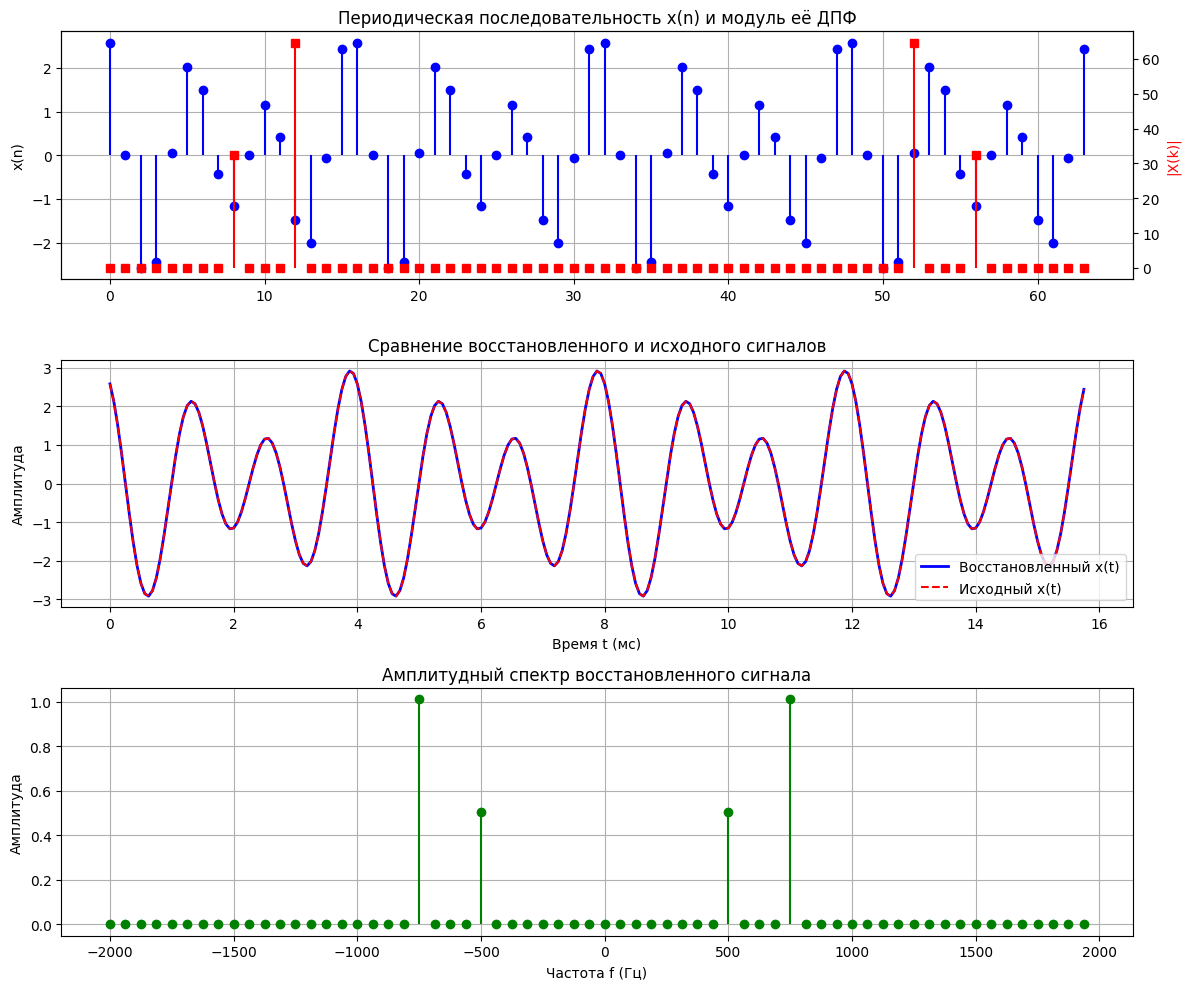

Максимальная погрешность восстановления: 3.35e-14


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N, f_d = 64, 4000
T = 1 / f_d
A1, A2, f1, f2 = 1.01, 2.02, 500, 750

n = np.arange(N)
x_n = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi/8)
X = np.fft.fft(x_n)

# Формирование X_a(k) согласно формуле задания (эквивалентно fftshift)
X_a = np.fft.fftshift(X)
k = np.arange(-N//2, N//2)

# Вектор времени и восстановление сигнала x(t) матричным умножением
t = np.arange(0, (N - 1) * T + 0.25 * T, 0.25 * T)
exp_mat = np.exp(1j * 2 * np.pi * np.outer(t, k) / (N * T))
x_rec = np.real((1 / N) * np.dot(exp_mat, X_a))

# Исходный аналоговый сигнал и спектр
x_orig = A1 * np.cos(2 * np.pi * f1 * t + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * t + np.pi/8)
f_k = k * f_d / N
spectrum_amp = np.abs(X_a) / N

# Графики
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10))

ax1.stem(n, x_n, linefmt='b-', markerfmt='bo', basefmt=" ")
ax1.set_title('Периодическая последовательность x(n) и модуль её ДПФ')
ax1.set_ylabel('x(n)')
ax1.grid(True)
ax1_twin = ax1.twinx()
ax1_twin.stem(np.arange(N), np.abs(X), linefmt='r-', markerfmt='rs', basefmt=" ")
ax1_twin.set_ylabel('|X(k)|', color='r')

ax2.plot(t * 1000, x_rec, 'b-', linewidth=2, label='Восстановленный x(t)')
ax2.plot(t * 1000, x_orig, 'r--', linewidth=1.5, label='Исходный x(t)')
ax2.set_title('Сравнение восстановленного и исходного сигналов')
ax2.set_xlabel('Время t (мс)')
ax2.set_ylabel('Амплитуда')
ax2.grid(True)
ax2.legend()

ax3.stem(f_k, spectrum_amp, linefmt='g-', markerfmt='go', basefmt=" ")
ax3.set_title('Амплитудный спектр восстановленного сигнала')
ax3.set_xlabel('Частота f (Гц)')
ax3.set_ylabel('Амплитуда')
ax3.grid(True)

plt.tight_layout()
plt.show()

print(f"Максимальная погрешность восстановления: {np.max(np.abs(x_rec - x_orig)):.2e}")

**Результаты и интерпретация**

График восстановленного сигнала $x(t)$ идеально совпадает с графиком исходного аналогового сигнала. Максимальная абсолютная погрешность восстановления составляет порядка $10^{-14}$ (уровень машинной точности). Это подтверждает, что ДПФ конечной последовательности содержит полную информацию для точного восстановления исходного полосно-ограниченного периодического сигнала.

### Часть 2. Пункт 6. Интерпретация результатов восстановления сигнала

**Результаты и интерпретация**

1. **Связь модуля ДПФ со спектром аналогового сигнала:**
   - Модуль ДПФ $|X[k]|$ представляет собой дискретные отсчёты амплитудного спектра аналогового сигнала на частотах $f_k = k \cdot f_d / N$.
   - Для вещественного сигнала спектр симметричен: $|X[N-k]| = |X[k]|$, поэтому каждая гармоника исходного сигнала даёт два пика на частотах $\pm f$.
   - На графике амплитудного спектра (нормированного на $N$) видны пики на частотах $\pm 500$ Гц ($k = \pm 8$) и $\pm 750$ Гц ($k = \pm 12$) с амплитудами $A_1/2 = 0.505$ и $A_2/2 = 1.01$ соответственно. Это соответствует теоретическому спектру суммы двух косинусов, где каждая гармоника $A\cos(2\pi f t + \varphi)$ имеет спектральные составляющие с амплитудой $A/2$ на частотах $\pm f$.

2. **Результат визуального сравнения восстановленного и исходного сигналов:**
   - Восстановленный сигнал $x(t)$ и исходный аналоговый сигнал полностью совпадают (максимальная погрешность $\approx 3.35 \times 10^{-14}$, что соответствует уровню машинной точности).
   - Это подтверждает, что при соблюдении **теоремы Котельникова** ($f_d > 2f_{max}$) набор из $N$ отсчётов ДПФ содержит полную информацию для точного восстановления непрерывного периодического сигнала.
   - В нашем случае: максимальная частота сигнала $f_{max} = 750$ Гц, частота Найквиста $f_d/2 = 2000$ Гц. Условие $f_d > 2f_{max}$ выполнено ($4000 > 1500$), поэтому наложения спектров (алиасинга) не происходит, и восстановление происходит без потерь.

### Часть 2. Пункт 7. Проверка равенства Парсеваля
Программно вычислена энергия сигнала во временной области (левая часть равенства) и энергия в частотной области (правая часть равенства). Результаты вычислений приведены ниже.

In [13]:
# Энергия сигнала во временной области
E_time = np.sum(np.abs(x_n)**2)

# Энергия сигнала в частотной области (согласно равенству Парсеваля)
E_freq = (1 / N) * np.sum(np.abs(X)**2)

print(f"Энергия во временной области:   {E_time:.6f}")
print(f"Энергия в частотной области:    {E_freq:.6f}")
print(f"Абсолютная разница:             {np.abs(E_time - E_freq):.2e}")

Энергия во временной области:   163.216000
Энергия в частотной области:    163.216000
Абсолютная разница:             0.00e+00


**Результаты и интерпретация**

1. **Численная проверка:** Энергия сигнала во временной области $E_{time} = 163.216$ в точности равна энергии в частотной области $E_{freq} = 163.216$. Абсолютная разница составляет $0.00$, что соответствует машинной точности вычислений.

2. **Аналитическое подтверждение:** Для суммы двух ортогональных гармоник $x[n] = A_1\cos(\omega_1 n + \varphi_1) + A_2\cos(\omega_2 n + \varphi_2)$ энергия вычисляется по формуле:
   $$E = \frac{N}{2}(A_1^2 + A_2^2) = \frac{64}{2}(1.01^2 + 2.02^2) = 32 \cdot 5.1005 = 163.216$$
   что полностью совпадает с результатом программного расчёта.

3. **Физический смысл равенства Парсеваля:** Равенство Парсеваля выражает **закон сохранения энергии** при переходе между временным и частотным представлениями сигнала. Полная энергия дискретного сигнала, вычисленная как сумма квадратов модулей его отсчётов во временной области, в точности равна сумме квадратов модулей спектральных составляющих, нормированной на длину последовательности $N$. Это подтверждает, что ДПФ является унитарным (энергетически эквивалентным) преобразованием — оно не создаёт и не уничтожает энергию сигнала, а лишь перераспределяет её по частотным составляющим.

## Выводы

В ходе выполнения практической работы были изучены математическое описание линейных дискретных систем и методы спектрального анализа на основе дискретного преобразования Фурье.

В первой части работы было показано, что импульсная характеристика рекурсивного звена второго порядка имеет бесконечную длину, что характерно для БИХ-фильтров. Реакция системы на прямоугольный импульс, вычисленная через линейную свёртку и через разностное уравнение, дала идентичные результаты, что подтверждает эквивалентность временных описаний линейных стационарных систем. Анализ карты нулей и полюсов подтвердил устойчивость системы, так как все полюсы лежат внутри единичной окружности. Исследование частотных характеристик показало, что система является фильтром нижних частот с резонансным пиком вблизи частоты полюса и провалом на частоте нуля.

Во второй части работы было исследовано дискретное преобразование Фурье периодической последовательности, состоящей из двух гармоник. ДПФ дало спектральные пики на соответствующих частотах с амплитудами, пропорциональными амплитудам исходных гармоник, а также их зеркальные отражения. Применение обратного ДПФ позволило восстановить исходную последовательность с погрешностью на уровне машинной точности, что подтверждает обратимость преобразования. Восстановление непрерывного аналогового сигнала по отсчётам ДПФ дало результат, идентичный исходному сигналу, что демонстрирует полноту информации в спектральных коэффициентах при соблюдении теоремы Котельникова. Проверка равенства Парсеваля подтвердила закон сохранения энергии при переходе между временной и частотной областями.

Полученные результаты подтверждают фундаментальные свойства линейных дискретных систем и дискретного преобразования Фурье, а также демонстрируют их практическую применимость для анализа и синтеза сигналов.